In [1]:
import warnings
import time

import pandas as pd
import numpy as np

import pickle

import matplotlib as mtl
from matplotlib import pyplot as plt
from matplotlib.ticker import ScalarFormatter
import seaborn as sns
import plotly.graph_objects as go

import lifelines
from lifelines.utils import concordance_index
from lifelines.statistics import logrank_test
from sksurv.util import Surv
from sksurv.metrics import concordance_index_ipcw

import os, sys

import tensorflow as tf
import tensorflow_probability as tfp

from tensorflow import keras
from tensorflow.keras import optimizers, initializers, regularizers, layers

from tensorflow.keras.callbacks import Callback
from tqdm.keras import TqdmCallback
from tqdm import tqdm

import scipy.stats as stats
from scipy.stats import norm, t
from scipy.special import gamma

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, KFold

sys.path.insert(0, "../../src")

import thetaflow as thf
print("thetaflow version: {}".format(thf.__version__))

2026-10-29 12:48:52.659401: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793288932.676330   35587 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793288932.681320   35587 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793288932.694100   35587 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793288932.694127   35587 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793288932.694130   35587 computation_placer.cc:177] computation placer alr

thetaflow version: 0.0.38


I0000 00:00:1793288935.675678   35587 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3730 MB memory:  -> device: 0, name: NVIDIA GeForce GTX 1660, pci bus id: 0000:01:00.0, compute capability: 7.5


In [2]:
df = pd.read_csv("../data/00_clean/metabric_full_data.csv")

print("Data dimension: {}".format(df.shape))

# Filter only the variables that are strictly going to be used in the study
df = df.loc[:, ["PATIENT_ID", "time_months", "delta", "AGE_AT_DIAGNOSIS", "CLAUDIN_SUBTYPE", "NPI"] + list(df.columns[8:])]
df.columns = ["patient_id", "time", "delta", "age_at_diagnosis", "pam50_subtype", "npi"] + list(df.columns[6:])

# Remove patients whose delta and time observations are NULL
df = df.loc[~pd.isnull(df["delta"]), :]

df.head()

Data dimension: (2245, 181)


,patient_id,time,delta,age_at_diagnosis,pam50_subtype,npi,FOXO3,TP53,NCOR1,PIK3CA,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-0002,84.633333,0.0,43.19,LumA,4.020,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
1,MB-0005,153.300000,1.0,48.87,LumB,4.030,0,0,1,1,...,0,0,0,0,0,0,0,0,0,0
2,MB-0006,164.933333,0.0,47.68,LumB,4.050,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,MB-0008,18.800000,1.0,76.97,LumB,6.080,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
4,MB-0010,2.933333,1.0,78.77,LumB,4.062,0,1,1,1,...,0,0,0,0,0,0,0,0,0,0


In [3]:
df.describe()

,time,delta,age_at_diagnosis,npi,FOXO3,TP53,NCOR1,PIK3CA,TG,GATA3,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
count,2237.000000,2237.000000,2237.000000,2137.000000,2237.000000,2237.000000,2237.000000,2237.000000,2237.000000,2237.000000,...,2237.000000,2237.000000,2237.000000,2237.000000,2237.000000,2237.000000,2237.000000,2237.000000,2237.000000,2237.000000
mean,110.610505,0.407242,60.935346,4.048411,0.018775,0.367009,0.041574,0.483236,0.062584,0.122485,...,0.004917,0.001341,0.004023,0.006258,0.003129,0.001341,0.000894,0.003576,0.000894,0.002235
std,78.198971,0.491430,12.963702,1.168405,0.145307,0.509167,0.212673,0.616783,0.253101,0.342593,...,0.069966,0.036604,0.063315,0.078880,0.063366,0.036604,0.029894,0.059708,0.029894,0.047235
min,0.033333,0.000000,21.930000,1.020000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,41.000000,0.000000,51.290000,3.050000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,100.000000,0.000000,61.810000,4.044000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,171.100000,1.000000,70.320000,5.040000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,389.333333,1.000000,96.290000,7.200000,2.000000,5.000000,2.000000,4.000000,2.000000,2.000000,...,1.000000,1.000000,1.000000,1.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [4]:
print("NA PAM50 subtypes: {}".format( np.sum(pd.isna(df["pam50_subtype"])) ))
print(df["pam50_subtype"].value_counts())

NA PAM50 subtypes: 382
pam50_subtype
LumA           671
LumB           452
Her2           218
Basal          196
claudin-low    178
Normal         134
NC               6
Name: count, dtype: int64


In [5]:
df_clean = df.loc[ df["pam50_subtype"] != "NC" ]

df_clean = df_clean.loc[~pd.isna(df_clean["pam50_subtype"]), :]
df_clean["pam50_subtype"].value_counts()

pam50_subtype
LumA           671
LumB           452
Her2           218
Basal          196
claudin-low    178
Normal         134
Name: count, dtype: int64

LumA - 671
LumB - 452
claudin-low - 178
Her2 - 218
Basal - 196
Normal - 134


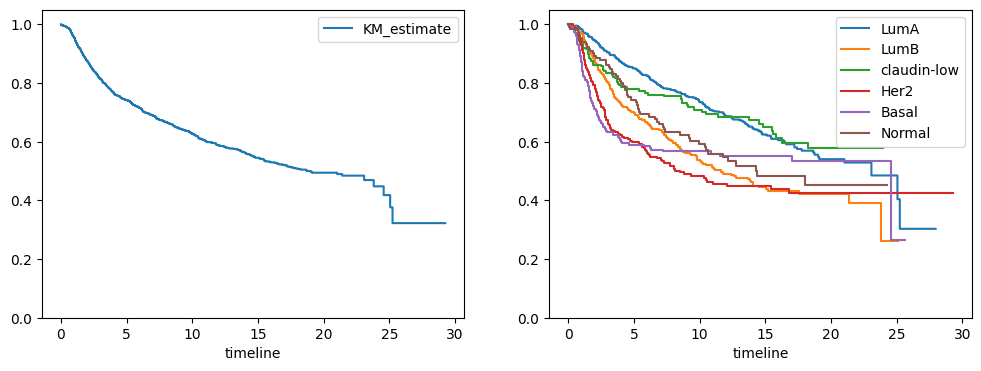

In [6]:
fig, ax = plt.subplots(nrows = 1, ncols = 2, figsize = (12,4))

unique_pam50_subtypes = df_clean["pam50_subtype"].unique()

km = lifelines.KaplanMeierFitter()
km.fit(df_clean["time"] / 12, df_clean["delta"])
km.plot(ax = ax[0], ci_show = False, show_censors = False)

for i, subtype in enumerate(unique_pam50_subtypes):
    time = df_clean.loc[df_clean["pam50_subtype"] == subtype, "time"]
    delta = df_clean.loc[df_clean["pam50_subtype"] == subtype, "delta"]
    print(subtype, "-", len(time))
    km = lifelines.KaplanMeierFitter()
    # Years
    km.fit(time / 12, delta)
    km.plot(ax = ax[1], ci_show = False, show_censors = False, label = subtype)

ax[0].set_ylim(0,1.05)
ax[1].set_ylim(0,1.05)
plt.show()

In [7]:
df_train, df_test = train_test_split(df_clean, test_size = 0.25, stratify = df_clean["delta"], random_state = 10)

df_train = df_train.reset_index(drop = True)
df_test = df_test.reset_index(drop = True)

print("Distribution of PAM50 subtypes in train set:")
print( df_train["pam50_subtype"].value_counts() / df_train["pam50_subtype"].shape[0] )

print("\nDistribution of PAM50 subtypes in test set:")
print( df_test["pam50_subtype"].value_counts() / df_test["pam50_subtype"].shape[0] )

Distribution of PAM50 subtypes in train set:
pam50_subtype
LumA           0.363636
LumB           0.245310
Her2           0.121212
Basal          0.103896
claudin-low    0.095238
Normal         0.070707
Name: count, dtype: float64

Distribution of PAM50 subtypes in test set:
pam50_subtype
LumA           0.360691
LumB           0.241901
Basal          0.112311
Her2           0.107991
claudin-low    0.099352
Normal         0.077754
Name: count, dtype: float64


In [8]:
df_train.to_csv("../data/00_clean/metabric_train_data.csv", index = False)
df_test.to_csv("../data/00_clean/metabric_test_data.csv", index = False)

In [9]:
from sklearn.preprocessing import OneHotEncoder

In [10]:
oh = OneHotEncoder(drop = ["LumA"])

df_train_oh = oh.fit_transform(df_train.loc[:,"pam50_subtype":"pam50_subtype"]).todense()
df_test_oh = oh.transform(df_test.loc[:,"pam50_subtype":"pam50_subtype"]).todense()

df_train2 = pd.concat([df_train, pd.DataFrame(df_train_oh)], axis = 1)
df_test2 = pd.concat([df_test, pd.DataFrame(df_test_oh)], axis = 1)

df_train2.head(2)

,patient_id,time,delta,age_at_diagnosis,pam50_subtype,npi,FOXO3,TP53,NCOR1,PIK3CA,...,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS,0,1,2,3,4
0,MB-5223,136.7,1.0,42.05,claudin-low,4.044,0,1,0,0,...,0,0,0,0,0,0.0,0.0,0.0,0.0,1.0
1,MB-5576,194.0,0.0,67.79,LumB,4.040,0,0,0,0,...,0,0,0,0,0,0.0,0.0,1.0,0.0,0.0


In [11]:
df_train3 = df_train2.iloc[:, [0,1,2,3,5,-5,-4,-3,-2,-1] + list(np.arange(6, df_train.shape[1])) ]
df_train3.columns = ["patient_id", "time", "delta", "age_at_diagnosis", "npi"] + list(oh.get_feature_names_out()) + list(df_train2.columns[6:(df_train2.shape[1]-5)])

df_test3 = df_test2.iloc[:, [0,1,2,3,5,-5,-4,-3,-2,-1] + list(np.arange(6, df_test.shape[1])) ]
df_test3.columns = ["patient_id", "time", "delta", "age_at_diagnosis", "npi"] + list(oh.get_feature_names_out()) + list(df_test2.columns[6:(df_test2.shape[1]-5)])

df_train3.head()

,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-5223,136.700000,1.0,42.05,4.044,0.0,0.0,0.0,0.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,MB-5576,194.000000,0.0,67.79,4.040,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-6238,172.966667,1.0,84.87,3.058,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-0379,119.500000,1.0,48.22,4.058,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-4708,18.700000,1.0,63.03,4.036,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


We finally have almost everything ready to start fitting our new class of AFT models with neural network components. The only thing left is to find a way to deal with all these gene mutations count values. In a standard gene expression study, there are many fixed routines such as the Variance Stabilizing Transformations (VST) natively applied in biostatistics packages in R. Although here we also model count data, here these values are much smaller, while there we may have thousands of counts for each gene. Because of that, the pre-processing of such mutations seems much closer to categorical data than they are to proper count data, with operations that transform them into quasi-continuous values.

If we consider a simple One-Hot-Encoding scheme for all genes, we will end up quintuplicating the number of columns in our dataset and the model will likely overfit, while also being hard to be interpreted in general. For that reason, we will be exploring here a shared neural network count data embedding for all gene mutation columns.

This discussion of embeddings is important, since for important genes, there may be a huge difference between a patient having a zero count of mutations to them and a single mutation, for example. If we consider these data as categorical, we maximize flexibility at the cost of overfitting, and if we simply transform them usin a $\log(x + 1)$ function for example, we end up attributing an arbitrary scale to what the difference between having zero counts to one count (for instance) means. Ideally, that difference should be obtained by the model, as it has an interpretability purpose in this study.

In [12]:
X_raw_counts_train = df_train3.iloc[:,10:]
X_raw_counts_train_clipped = np.clip(X_raw_counts_train, a_min = 0, a_max = 3)
df_train4 = df_train3.copy()
df_train4.iloc[:,10:] = X_raw_counts_train_clipped

X_raw_counts_test = df_test3.iloc[:,10:]
X_raw_counts_test_clipped = np.clip(X_raw_counts_test, a_min = 0, a_max = 3)
df_test4 = df_test3.copy()
df_test4.iloc[:,10:] = X_raw_counts_test_clipped

df_train4.head()

,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-5223,136.700000,1.0,42.05,4.044,0.0,0.0,0.0,0.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,MB-5576,194.000000,0.0,67.79,4.040,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-6238,172.966667,1.0,84.87,3.058,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-0379,119.500000,1.0,48.22,4.058,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-4708,18.700000,1.0,63.03,4.036,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [13]:
sc = StandardScaler()

df_train5 = df_train4.copy()
df_test5 = df_test4.copy()

df_train5.iloc[:,3:5] = sc.fit_transform(df_train4.iloc[:,3:5])
df_test5.iloc[:,3:5] = sc.transform(df_test5.iloc[:,3:5])

df_train5.head()

,patient_id,time,delta,age_at_diagnosis,npi,pam50_subtype_Basal,pam50_subtype_Her2,pam50_subtype_LumB,pam50_subtype_Normal,pam50_subtype_claudin-low,...,NT5E,NRAS,CCND3,AGTR2,MBL2,SIAH1,STMN2,RASGEF1B,SMARCB1,HRAS
0,MB-5223,136.700000,1.0,-1.472877,-0.016511,0.0,0.0,0.0,0.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,MB-5576,194.000000,0.0,0.497740,-0.020040,0.0,0.0,1.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,MB-6238,172.966667,1.0,1.805360,-0.886508,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
3,MB-0379,119.500000,1.0,-1.000511,-0.004158,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,MB-4708,18.700000,1.0,0.133321,-0.023570,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [14]:
df_train5.to_csv("../data/01_mlready/metabric_train.csv", index = False)
df_test5.to_csv("../data/01_mlready/metabric_test.csv", index = False)

### Preparing Cross Validation Data

In [16]:
from sklearn.model_selection import StratifiedKFold

kf = StratifiedKFold(n_splits = 5, shuffle = True, random_state = 10)

cv_indices = []

for fold, (train_idx, test_idx) in enumerate(kf.split(df_clean, df_clean["delta"])):
    cv_indices.append({
        "train": train_idx,
        "test": test_idx
    })
    
    print(f"Fold {fold + 1} | Train: {len(train_idx)} patients | Test: {len(test_idx)} patients")

Fold 1 | Train: 1479 patients | Test: 370 patients
Fold 2 | Train: 1479 patients | Test: 370 patients
Fold 3 | Train: 1479 patients | Test: 370 patients
Fold 4 | Train: 1479 patients | Test: 370 patients
Fold 5 | Train: 1480 patients | Test: 369 patients


In [39]:
def prepare_train_test(df, train_indices, test_indices):
    df_train = df.iloc[train_indices, :].reset_index(drop = True)
    df_test = df.iloc[test_indices, :].reset_index(drop = True)

    # Create dummy variables for the PAM50 classes in the dataset
    oh = OneHotEncoder(drop = ["LumA"])

    df_train_oh = oh.fit_transform(df_train.loc[:,"pam50_subtype":"pam50_subtype"]).todense()
    df_test_oh = oh.transform(df_test.loc[:,"pam50_subtype":"pam50_subtype"]).todense()
    df_train2 = pd.concat([df_train, pd.DataFrame(df_train_oh)], axis = 1)
    df_test2 = pd.concat([df_test, pd.DataFrame(df_test_oh)], axis = 1)

    # Rearrange the variables for a more readable order
    df_train3 = df_train2.iloc[:, [0,1,2,3,5,-5,-4,-3,-2,-1] + list(np.arange(6, df_train.shape[1])) ]
    df_train3.columns = ["patient_id", "time", "delta", "age_at_diagnosis", "npi"] + list(oh.get_feature_names_out()) + list(df_train2.columns[6:(df_train2.shape[1]-5)])
    df_test3 = df_test2.iloc[:, [0,1,2,3,5,-5,-4,-3,-2,-1] + list(np.arange(6, df_test.shape[1])) ]
    df_test3.columns = ["patient_id", "time", "delta", "age_at_diagnosis", "npi"] + list(oh.get_feature_names_out()) + list(df_test2.columns[6:(df_test2.shape[1]-5)])

    # Clip gene mutation counts to 3. Those count values will be considered by a count embedding in the neural network input layer
    X_raw_counts_train = df_train3.iloc[:,10:]
    X_raw_counts_train_clipped = np.clip(X_raw_counts_train, a_min = 0, a_max = 3)
    df_train4 = df_train3.copy()
    df_train4.iloc[:,10:] = X_raw_counts_train_clipped
    
    X_raw_counts_test = df_test3.iloc[:,10:]
    X_raw_counts_test_clipped = np.clip(X_raw_counts_test, a_min = 0, a_max = 3)
    df_test4 = df_test3.copy()
    df_test4.iloc[:,10:] = X_raw_counts_test_clipped

    sc = StandardScaler()

    df_train5 = df_train4.copy()
    df_test5 = df_test4.copy()
    
    df_train5.iloc[:,3:5] = sc.fit_transform(df_train4.iloc[:,3:5])
    df_test5.iloc[:,3:5] = sc.transform(df_test5.iloc[:,3:5])

    return df_train5, df_test5

In [52]:
for i in range(len(cv_indices)):
    df_train_fold, df_test_fold = prepare_train_test(df_clean, cv_indices[i]["train"], cv_indices[i]["test"])
    df_train_fold.to_csv("../data/01_mlready/Cross Validation/{}_fold_train.csv".format(i+1))
    df_test_fold.to_csv("../data/01_mlready/Cross Validation/{}_fold_test.csv".format(i+1))